# Superstore Sales Profitability Analysis: Project Proposal


**Domain:** Retail and Sales Analytics (Multi-Market, Multi-Category)


## Project Overview

This project examines four years of transaction records (orders placed from 1 January 2011 to 31 December 2014) from a superstore business. Each record describes one order line: what was sold, to whom, where, how it was shipped, and what it earned or lost. The dataset contains 51,290 records and 27 columns.

The business records show sales volume, but volume alone does not show whether the business is healthy. This project looks at how much profit each part of the business generates and where losses come from.

## Business Problem

Sales managers need to know which sub-categories, markets, and customer segments make money and which lose it. The dataset shows high sales in some markets, but sales alone do not show whether the business is healthy. This analysis asks whether discounting is a major cause of losses, and where in the business the losses are concentrated, so that discount and pricing decisions can be based on evidence.

## Project Objectives

1. Calculate total sales, total profit, and profit margin (sum of profit ÷ sum of sales) for each Sub-Category and Market, 2011–2014.
2. Measure the share of order lines with negative profit at each discount level, and identify the lowest discount level at which more than half of order lines are loss-making.
3. Compare profit margin across the three Segments (Consumer, Corporate, Home Office) and the four Ship Modes, using ship_mode retained in the cleaned data.
4.Track sales, profit, and margin year by year from 2011 to 2014, and identify the market with the largest year-on-year change in margin.

## Business Value & Use Case

- **Sales and pricing managers** can use the discount-level results to set discount limits or approval rules.
- **Category managers** can decide which sub-categories to promote, reprice, or review.
- **Regional leads** can compare market performance on profit, not only on sales.
- **Finance teams** can use the margin figures to prioritise cost reviews in loss-making areas.

## Dataset Information

- **Source:** [Add the original source URL and attribution before submission]
- **File:** `superstore.csv` (copy in `data/`), with an identical copy uploaded as `superstore_data.csv`
- **Format:** CSV, UTF-8 encoded
- **Size:** 51,290 rows × 27 columns
- **Time period:** Order dates from 2011-01-01 to 2014-12-31. Ship dates extend to 2015-01-07.
- **One record represents:** one order line, identified by `Row.ID`. `Order.ID` may appear on more than one row.

**Key fields**

| Field | Meaning |
|---|---|
| Order.Date, Ship.Date | Dates the order was placed and shipped (stored as text) |
| Category, Sub.Category, Product.Name | What was sold |
| Sales, Quantity, Discount | Revenue, units, and discount applied |
| Profit, Shipping.Cost | Profit on the line and shipping cost |
| Segment, Customer.ID | Customer type and identifier |
| Market, Region, Country, State, City | Where the order was made |
| Ship.Mode, Order.Priority | Shipping method and priority |

## Planned Analysis

No results are stated here. Figures will be reported only after the analysis is run.

**Cleaning:** Convert dates from text to datetime, check for missing values, duplicates, and negative sales, and review redundant columns (`记录数`, `Market2`, `weeknum`, `Year`).

**Feature creation:** profit_status, ship_days, unit_price, quarter.

**Market and country comparison:** Sales, profit, and margin by country, city, and region.

**Charts:** Margin by Category and Sub-Category (bar), sales and profit by year (line), Discount vs Profit (scatter with trend line), and margin by Market and Category (heatmap).

**Tools:** Python 3, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook.

## Scope & Limitations

**In scope:** Descriptive analysis of order-line sales, profit, discount, and margin, 2011–2014.

**Out of scope:** Forecasting, customer churn, and costs not in the dataset (overheads, staff, rent).

**Assumptions:** Profit values are correct as recorded, and the dataset is complete for the period.

**Constraints:** Dates are stored as text, no negative sales values appear (returns seem unrecorded), Region and Market labels overlap, and the source must be verified before sharing.

## Data notes:
* One row has zero sales and was removed.
* Region names repeat across markets (for example, “Central,” “South,” and “North”), so all region groupings use market and region together.
* Each row is an order line, not an order. Counts of “orders” are order lines unless stated otherwise.
* Average discount is an unweighted mean across lines. Sales-weighted figures are used where a discount-based margin is reported.
* No negative sales values appear, so returns are assumed to be unrecorded.

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv("D:\Capstone_project\superstore_data.csv")

In [61]:
print("Dataset Loaded ")
print("Number of rows and columns:",df.shape)
df.head(5)

Dataset Loaded 
Number of rows and columns: (51290, 27)


,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,记录数,Order.Date,Order.ID,...,Sales,Segment,Ship.Date,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-07 00:00:00.000,CA-2011-130813,...,19,Consumer,2011-01-09 00:00:00.000,Second Class,4.37,California,Paper,2011,North America,2
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-21 00:00:00.000,CA-2011-148614,...,19,Consumer,2011-01-26 00:00:00.000,Standard Class,0.94,California,Paper,2011,North America,4
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05 00:00:00.000,CA-2011-118962,...,21,Consumer,2011-08-09 00:00:00.000,Standard Class,1.81,California,Paper,2011,North America,32
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05 00:00:00.000,CA-2011-118962,...,111,Consumer,2011-08-09 00:00:00.000,Standard Class,4.59,California,Paper,2011,North America,32
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,2011-09-29 00:00:00.000,CA-2011-146969,...,6,Consumer,2011-10-03 00:00:00.000,Standard Class,1.32,California,Paper,2011,North America,40


In [62]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Category        51290 non-null  str    
 1   City            51290 non-null  str    
 2   Country         51290 non-null  str    
 3   Customer.ID     51290 non-null  str    
 4   Customer.Name   51290 non-null  str    
 5   Discount        51290 non-null  float64
 6   Market          51290 non-null  str    
 7   记录数             51290 non-null  int64  
 8   Order.Date      51290 non-null  str    
 9   Order.ID        51290 non-null  str    
 10  Order.Priority  51290 non-null  str    
 11  Product.ID      51290 non-null  str    
 12  Product.Name    51290 non-null  str    
 13  Profit          51290 non-null  float64
 14  Quantity        51290 non-null  int64  
 15  Region          51290 non-null  str    
 16  Row.ID          51290 non-null  int64  
 17  Sales           51290 non-null  int64  
 1

In [63]:
df.dtypes

Category              str
City                  str
Country               str
Customer.ID           str
Customer.Name         str
Discount          float64
Market                str
记录数                 int64
Order.Date            str
Order.ID              str
Order.Priority        str
Product.ID            str
Product.Name          str
Profit            float64
Quantity            int64
Region                str
Row.ID              int64
Sales               int64
Segment               str
Ship.Date             str
Ship.Mode             str
Shipping.Cost     float64
State                 str
Sub.Category          str
Year                int64
Market2               str
weeknum             int64
dtype: object

In [64]:
df.columns

Index(['Category', 'City', 'Country', 'Customer.ID', 'Customer.Name',
       'Discount', 'Market', '记录数', 'Order.Date', 'Order.ID', 'Order.Priority',
       'Product.ID', 'Product.Name', 'Profit', 'Quantity', 'Region', 'Row.ID',
       'Sales', 'Segment', 'Ship.Date', 'Ship.Mode', 'Shipping.Cost', 'State',
       'Sub.Category', 'Year', 'Market2', 'weeknum'],
      dtype='str')

## Initial Dataset Observations
The file loaded cleanly with 51,290 rows and 27 columns, and it contains no missing values and no duplicate rows. Order dates run from 1 January 2011 to 31 December 2014, and every ship date falls on or after its order date. Discounts range from 0% to 85%, and 12,544 order lines (about 24.5%) show negative profit. Sales are never negative, although one row has a sales value of zero.

At this stage, I have only completed an initial inspection of the dataset. A closer examination of the data types, missing or unknown values, and distributions of important variables will be carried out during the next stages of the projec


# Data cleaning

In [65]:
df.duplicated().sum()

np.int64(0)

**zero duplicated values**

In [66]:
df.isnull().sum()

Category          0
City              0
Country           0
Customer.ID       0
Customer.Name     0
Discount          0
Market            0
记录数               0
Order.Date        0
Order.ID          0
Order.Priority    0
Product.ID        0
Product.Name      0
Profit            0
Quantity          0
Region            0
Row.ID            0
Sales             0
Segment           0
Ship.Date         0
Ship.Mode         0
Shipping.Cost     0
State             0
Sub.Category      0
Year              0
Market2           0
weeknum           0
dtype: int64

**zero null values**

In [67]:
df=df.drop(columns=["记录数"])

In [68]:
df=df.drop(columns=["Market2"])

In [69]:
df=df.drop(columns="weeknum")

In [70]:
df.columns=df.columns.str.lower().str.replace(".","_")

**Changed the column title to lower alphabets and replaced "." with "_"**

**Dropped columns<br>
"记录数" as of irrelevant data,<br>
"Market2" for it shows same as market the difference is the usa and canada are merged as north america,<br>
"weeknum" because it is fully derivable from year**

In [71]:
df["order_date"] = pd.to_datetime(df["order_date"]).dt.normalize()
df["ship_date"] = pd.to_datetime(df["ship_date"]).dt.normalize()

In [72]:
df["sales"] = df["sales"].astype(float).round(2)

In [73]:
df["profit"] = df["profit"].astype(float).round(2)

**Changed data types of "order_date" and "ship_date" to datetime, "sales" and "profit" to float dtype**

In [74]:
df["profit_status"]=np.select(
    [df["profit"]<0,df["profit"]>0],
    ["loss","profit"],
    default="break-even"
)

**Created a new column showing the the row is profit or loss or break even**

In [75]:
df["row_id"].nunique()

51290

In [76]:
df["ship_days"]=(df["ship_date"]-df["order_date"]).dt.days
assert (df["ship_days"]>=0).all(),"Ship date before order date"

df["unit_price"]=(df["sales"]/df["quantity"]).round(2)
assert(df["quantity"]>0).all(),"Zero or negative quantity found"

df["quarter"]=pd.to_datetime(df["order_date"]).dt.quarter

**Created a new columns <br>
"ship_days" showing the total days for the shipment<br>
"unit_price" showing price per unit by sales/quantity<br>
"quarter" shows which quarter of the year is it on<br>**

In [77]:
df.head(2)

,category,city,country,customer_id,customer_name,discount,market,order_date,order_id,order_priority,...,ship_date,ship_mode,shipping_cost,state,sub_category,year,profit_status,ship_days,unit_price,quarter
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,2011-01-07,CA-2011-130813,High,...,2011-01-09,Second Class,4.37,California,Paper,2011,profit,2,6.33,1
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,2011-01-21,CA-2011-148614,Medium,...,2011-01-26,Standard Class,0.94,California,Paper,2011,profit,5,9.50,1


In [78]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 28 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   category        51290 non-null  str           
 1   city            51290 non-null  str           
 2   country         51290 non-null  str           
 3   customer_id     51290 non-null  str           
 4   customer_name   51290 non-null  str           
 5   discount        51290 non-null  float64       
 6   market          51290 non-null  str           
 7   order_date      51290 non-null  datetime64[us]
 8   order_id        51290 non-null  str           
 9   order_priority  51290 non-null  str           
 10  product_id      51290 non-null  str           
 11  product_name    51290 non-null  str           
 12  profit          51290 non-null  float64       
 13  quantity        51290 non-null  int64         
 14  region          51290 non-null  str           
 15  row_id       

In [79]:
print(df.columns.tolist())

['category', 'city', 'country', 'customer_id', 'customer_name', 'discount', 'market', 'order_date', 'order_id', 'order_priority', 'product_id', 'product_name', 'profit', 'quantity', 'region', 'row_id', 'sales', 'segment', 'ship_date', 'ship_mode', 'shipping_cost', 'state', 'sub_category', 'year', 'profit_status', 'ship_days', 'unit_price', 'quarter']


In [80]:
df.loc[df["sales"]==0]

,category,city,country,customer_id,customer_name,discount,market,order_date,order_id,order_priority,...,ship_date,ship_mode,shipping_cost,state,sub_category,year,profit_status,ship_days,unit_price,quarter
46158,Office Supplies,Houston,United States,ZC-219104,Zuschuss Carroll,0.8,US,2014-06-20,US-2014-102288,Medium,...,2014-06-24,Standard Class,0.01,Texas,Appliances,2014,loss,4,0.0,2


In [81]:
print(df.loc[46158])

category                                            Office Supplies
city                                                        Houston
country                                               United States
customer_id                                               ZC-219104
customer_name                                      Zuschuss Carroll
discount                                                        0.8
market                                                           US
order_date                                      2014-06-20 00:00:00
order_id                                             US-2014-102288
order_priority                                               Medium
product_id                                          OFF-AP-10002906
product_name      Hoover Replacement Belt for Commercial Guardsm...
profit                                                        -1.11
quantity                                                          1
region                                          

In [82]:
df= df.drop(index=46158)

**Understood row number 46158 is the single cell having 0 sales so dropping it**

In [83]:
df["profit_margin"] =(df["profit"] / df["sales"].replace(0, pd.NA)).round(2)

In [84]:
df=df[["customer_id","customer_name","city","country","region","market","category",
       "sub_category","quantity","unit_price","discount","profit","profit_margin","sales",
       "order_date","quarter","year",
       "order_id","product_id", "product_name","ship_date",
       "row_id", "segment","order_priority", "shipping_cost",
       "state", "profit_status", "ship_days"]]

In [85]:
df.head(5)

,customer_id,customer_name,city,country,region,market,category,sub_category,quantity,unit_price,...,product_id,product_name,ship_date,row_id,segment,order_priority,shipping_cost,state,profit_status,ship_days
0,LS-172304,Lycoris Saunders,Los Angeles,United States,West,US,Office Supplies,Paper,3,6.33,...,OFF-PA-10002005,Xerox 225,2011-01-09,36624,Consumer,High,4.37,California,profit,2
1,MV-174854,Mark Van Huff,Los Angeles,United States,West,US,Office Supplies,Paper,2,9.50,...,OFF-PA-10002893,"Wirebound Service Call Books, 5 1/2"" x 4""",2011-01-26,37033,Consumer,Medium,0.94,California,profit,5
2,CS-121304,Chad Sievert,Los Angeles,United States,West,US,Office Supplies,Paper,3,7.00,...,OFF-PA-10000659,"Adams Phone Message Book, Professional, 400 Me...",2011-08-09,31468,Consumer,Medium,1.81,California,profit,4
3,CS-121304,Chad Sievert,Los Angeles,United States,West,US,Office Supplies,Paper,2,55.50,...,OFF-PA-10001144,Xerox 1913,2011-08-09,31469,Consumer,Medium,4.59,California,profit,4
4,AP-109154,Arthur Prichep,Los Angeles,United States,West,US,Office Supplies,Paper,1,6.00,...,OFF-PA-10002105,Xerox 223,2011-10-03,32440,Consumer,High,1.32,California,profit,4


In [86]:
print(df.columns.tolist())

['customer_id', 'customer_name', 'city', 'country', 'region', 'market', 'category', 'sub_category', 'quantity', 'unit_price', 'discount', 'profit', 'profit_margin', 'sales', 'order_date', 'quarter', 'year', 'order_id', 'product_id', 'product_name', 'ship_date', 'row_id', 'segment', 'order_priority', 'shipping_cost', 'state', 'profit_status', 'ship_days']


# Analysis

# Univariate

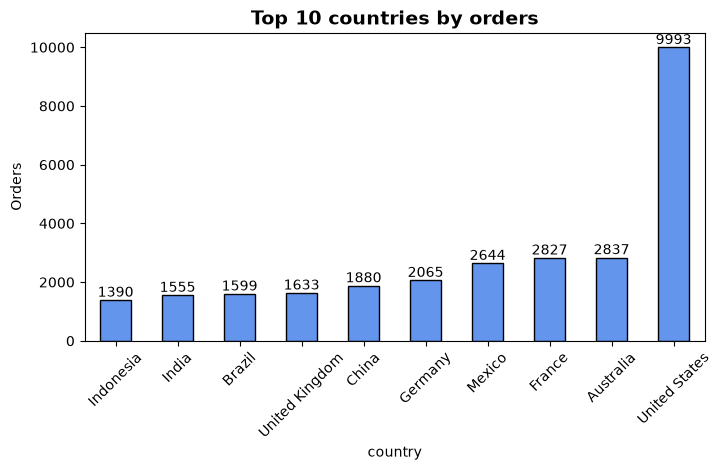

In [87]:
#Top countries by orders

ax=df["country"].value_counts().head(10).sort_values().plot(kind="bar",figsize=(8,4),color="cornflowerblue",edgecolor="black")
ax.bar_label(ax.containers[0])
plt.title("Top 10 countries by orders",fontsize=14,fontweight="bold")
plt.ylabel("Orders")
plt.xticks(rotation=45)
plt.show()

### Shows **USA** have the highest **orders** from whole data

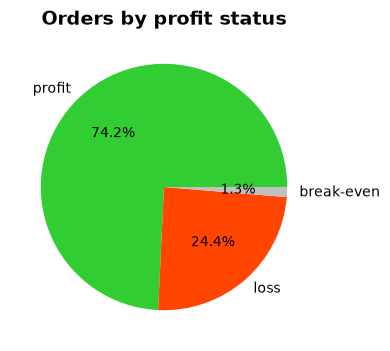

In [88]:
#Profit status

df["profit_status"].value_counts().plot(kind="pie",figsize=(10,4),autopct="%1.1f%%", colors=["limegreen", "orangered", "silver"])
plt.title("Orders by profit status",fontsize=14,fontweight="bold")
plt.show()

### Quarter of orders are in loss and **1.3%**  are in breakeven 

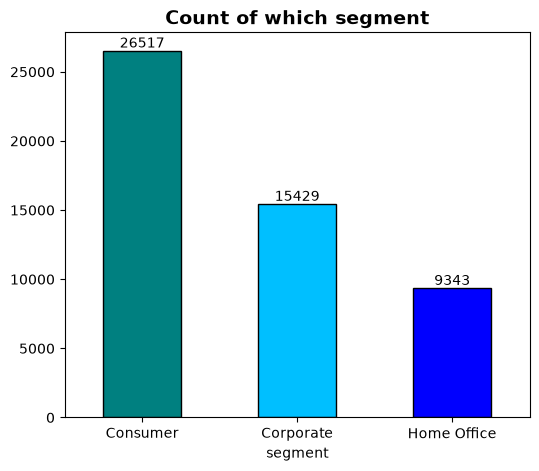

In [89]:
ax=df["segment"].value_counts().plot(kind="bar",color=["teal","deepskyblue","blue"],edgecolor="black",figsize=(6,5))
ax.bar_label(ax.containers[0])
plt.title("Count of which segment",fontsize=14,fontweight="bold")
plt.xticks(rotation=0)
plt.show()

### **Consumers** are the highest among 3, almost **3x** than **home office** buyers

In [90]:
#Top 5 loss over countries

top_loss=df.groupby("country")["profit"].sum().sort_values(ascending=True).head(5)
top_loss

country
Turkey        -98447.28
Nigeria       -80750.88
Netherlands   -41070.12
Honduras      -29482.32
Pakistan      -22446.63
Name: profit, dtype: float64

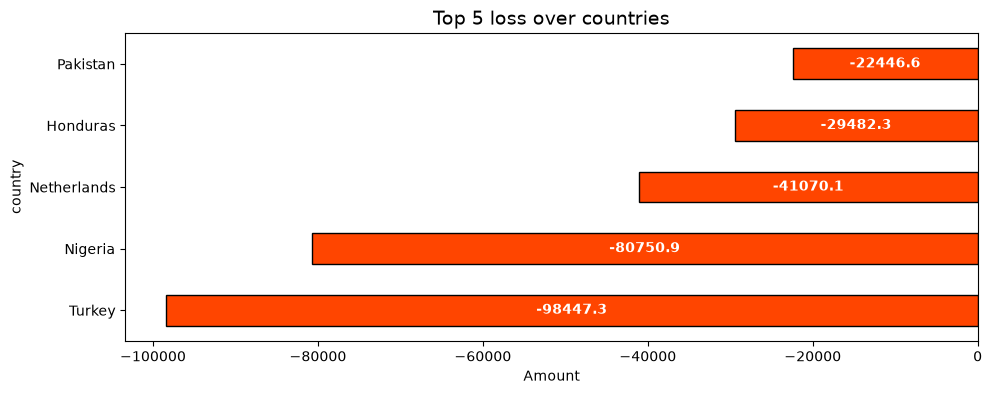

In [91]:
ax=top_loss.plot(kind="barh",figsize=(11,4),color=["orangered"],edgecolor="black")
ax.bar_label(ax.containers[0],label_type="center",fontweight="bold",color="white")
plt.title("Top 5 loss over countries",fontsize=14,)
plt.xlabel("Amount")
plt.xticks(rotation=0)
plt.show()

### Top 3 countries which have Loss are Turkey, Nigeria & Netherlands

# Bivariate

In [92]:
#Sales and Profit of top 5 countries

top=df.groupby("country")[["sales","profit"]].sum().sort_values("sales",ascending=False).head(5)
top

,sales,profit
country,,
United States,2297354.0,286397.65
Australia,925257.0,103907.20
France,858930.0,109028.99
China,700591.0,150683.08
Germany,628857.0,107322.77


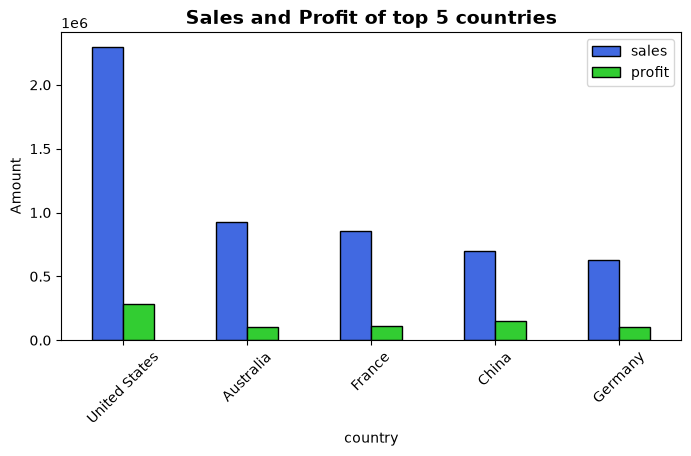

In [93]:
#Sales and Profit of top 5 countries

top.plot(kind="bar", figsize=(8,4),color=["royalblue","limegreen"],edgecolor="black")
plt.title("Sales and Profit of top 5 countries",fontsize=14,fontweight="bold")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.show()

### We found **USA** have the highest Sales and Profit

In [94]:
top_city=df.groupby("city")[["sales","profit"]].sum().sort_values("sales",ascending=False).head(5)
top_city

,sales,profit
city,,
New York City,256397.0,62036.93
Los Angeles,175857.0,30440.77
Manila,120896.0,-11158.54
Seattle,119552.0,29156.08
San Francisco,112690.0,17507.32


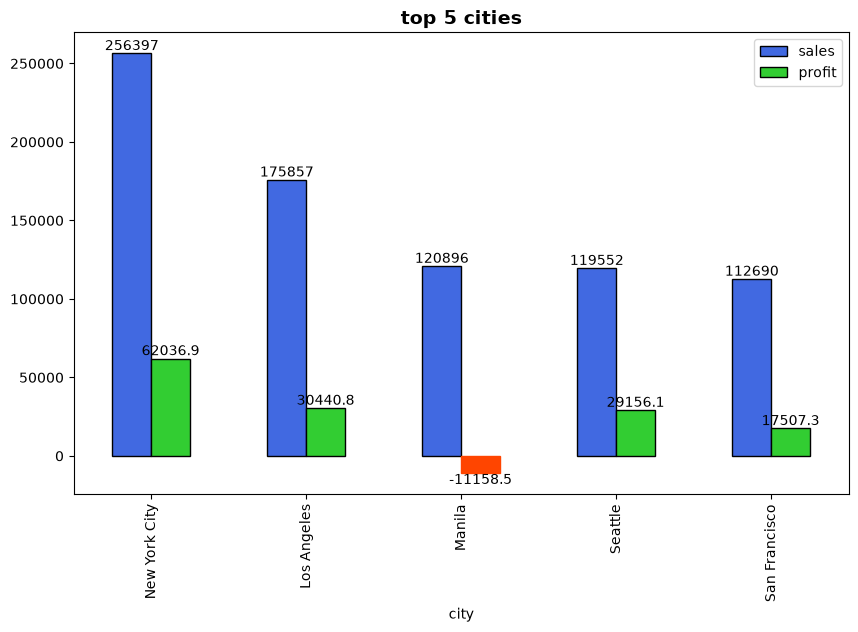

In [95]:
top_city = df.groupby("city")[["sales", "profit"]].sum().sort_values("sales", ascending=False).head(5)
ax = top_city.plot(kind="bar", edgecolor="black",color=["royalblue","limegreen"],figsize=(10,6))
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
for bar in ax.containers[1]:
    if bar.get_height()<0:
        bar.set_color("orangered")
plt.title("top 5 cities",fontsize=14,fontweight="bold")
plt.show()

## In top 5 cities 4 of them are from USA having top sales


In [96]:
#Count of regions overall

region_pie=df.groupby(["market","region"])["country"].nunique().sort_values(ascending=False)
region_pie

market  region        
Africa  Africa            45
EMEA    EMEA              40
LATAM   South             10
APAC    Southeast Asia     8
LATAM   Caribbean          8
APAC    Central Asia       6
        North Asia         6
EU      Central            6
        North              6
LATAM   Central            5
APAC    Oceania            3
EU      South              3
Canada  Canada             1
LATAM   North              1
US      Central            1
        East               1
        South              1
        West               1
Name: country, dtype: int64

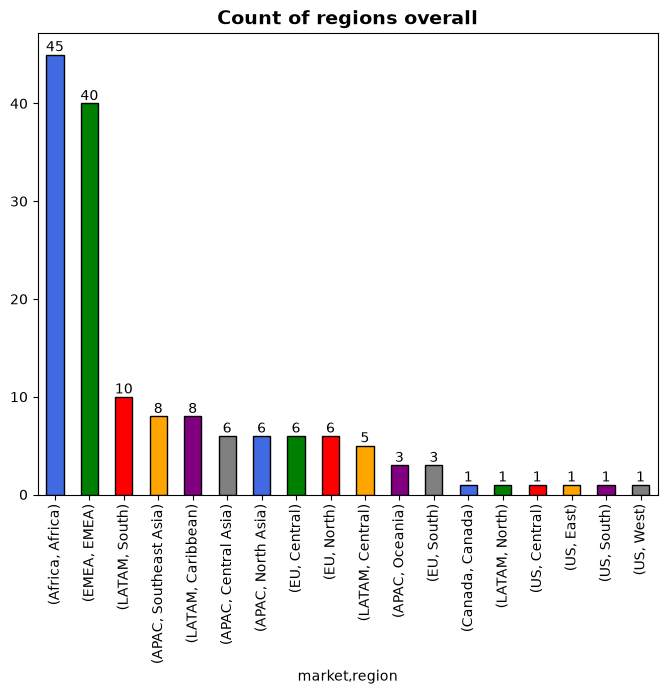

In [97]:
ax=region_pie.plot(kind="bar",figsize=(8,6),color=["royalblue","Green", "Red", "Orange", "Purple","Grey"],edgecolor=("black"))
ax.bar_label(ax.containers[0])
plt.title("Count of regions overall",fontsize=14,fontweight="bold")
plt.show()

### **African** region consists of *highest* country counts

### 

# Multivariate

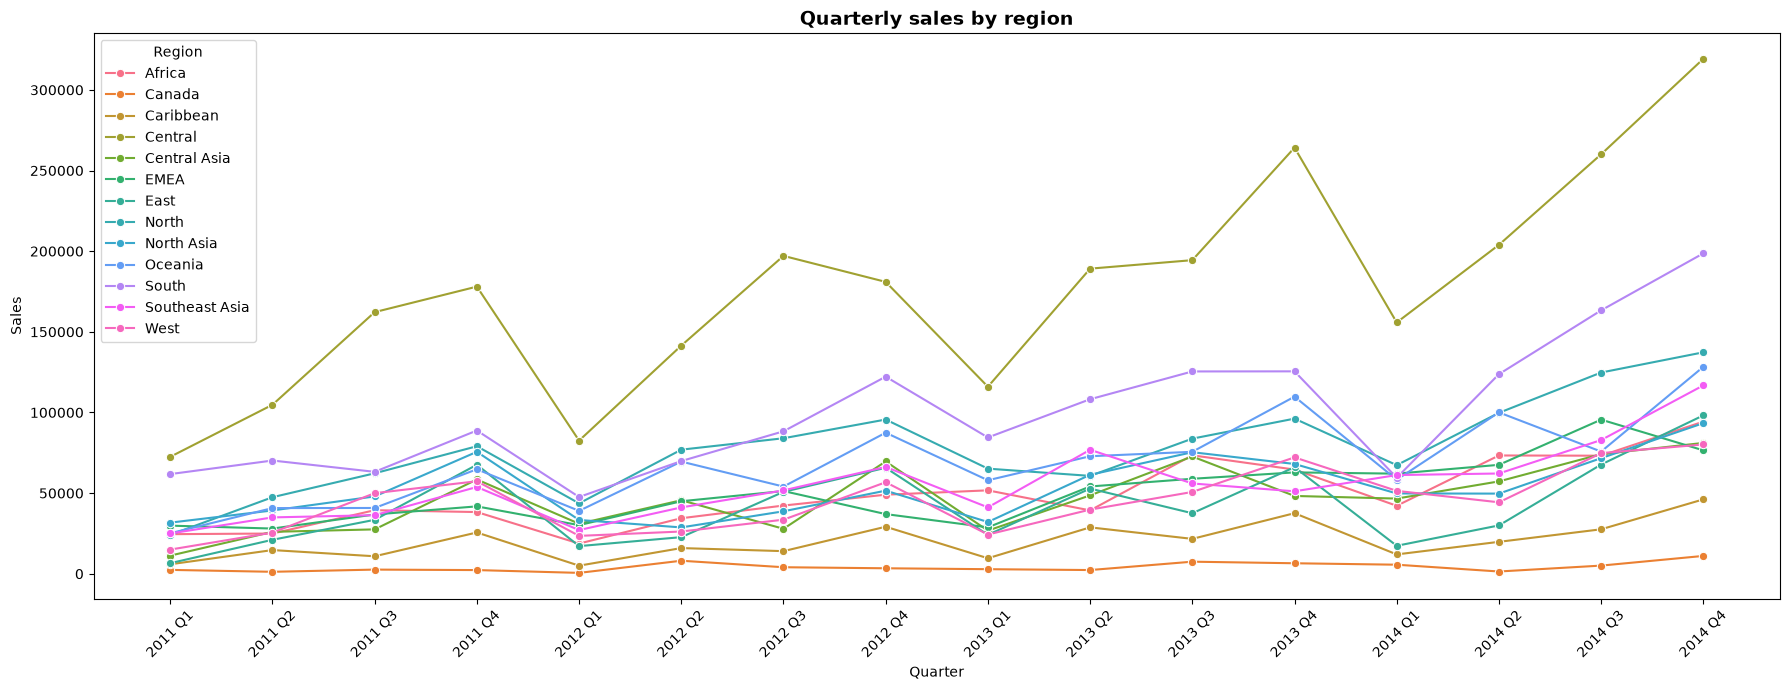

In [115]:
reg_q = df.groupby(["year", "quarter", "region"])["sales"].sum().reset_index()
reg_q["period"] = reg_q["year"].astype(str) + " Q" + reg_q["quarter"].astype(str)

plt.figure(figsize=(18, 7))
sns.lineplot(data=reg_q, x="period", y="sales", hue="region", marker="o")
plt.title("Quarterly sales by region", fontsize=14, fontweight="bold")
plt.xlabel("Quarter")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.legend(title="Region", loc="upper left")
plt.tight_layout()
plt.show()

#Grouped by region name alone, so regions with the same name in different markets are merged.

Inside region based analysis **CENTRAL** regions quarterly sales the highest

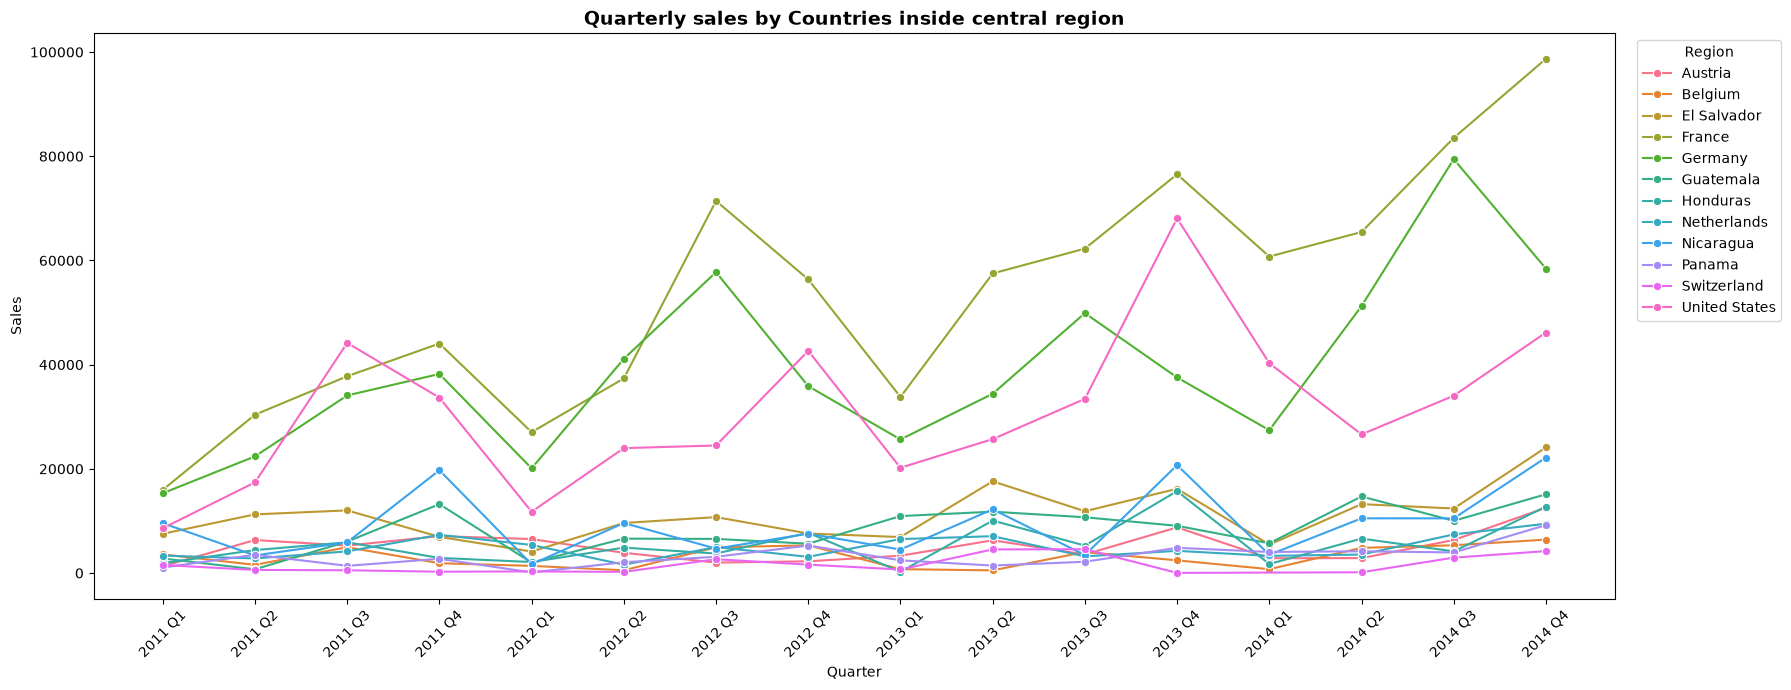

In [99]:
central_country = df[df["region"]=="Central"].groupby(["year", "quarter", "country"])["sales"].sum().reset_index()
central_country["period"] = central_country["year"].astype(str) + " Q" + central_country["quarter"].astype(str)

plt.figure(figsize=(18, 7))
sns.lineplot(data=central_country, x="period", y="sales", hue="country", marker="o")
plt.title("Quarterly sales by Countries inside central region", fontsize=14, fontweight="bold")
plt.xlabel("Quarter")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.legend(title="Region", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

Inside Central region **FRANCE** is the best performing country

In [100]:
best_country_q = (
    df.groupby(["year", "quarter","country","region"])["sales"].sum()
    .reset_index()
    .sort_values(["year", "quarter", "sales"], ascending=[True, True, False])
    .groupby(["year", "quarter"]).head(1)
    .rename(columns={"country": "best_country", "sales": "country_sales"})
)
best_country_q

,year,quarter,best_country,region,country_sales
90,2011,1,United States,South,44260.0
100,2011,2,Australia,Oceania,34853.0
286,2011,3,United States,West,49960.0
397,2011,4,United States,East,67596.0
421,2012,1,China,North Asia,32485.0
505,2012,2,Australia,Oceania,56302.0
640,2012,3,France,Central,71429.0
718,2012,4,Australia,Oceania,67706.0
826,2013,1,Australia,Oceania,49806.0
928,2013,2,Australia,Oceania,59028.0


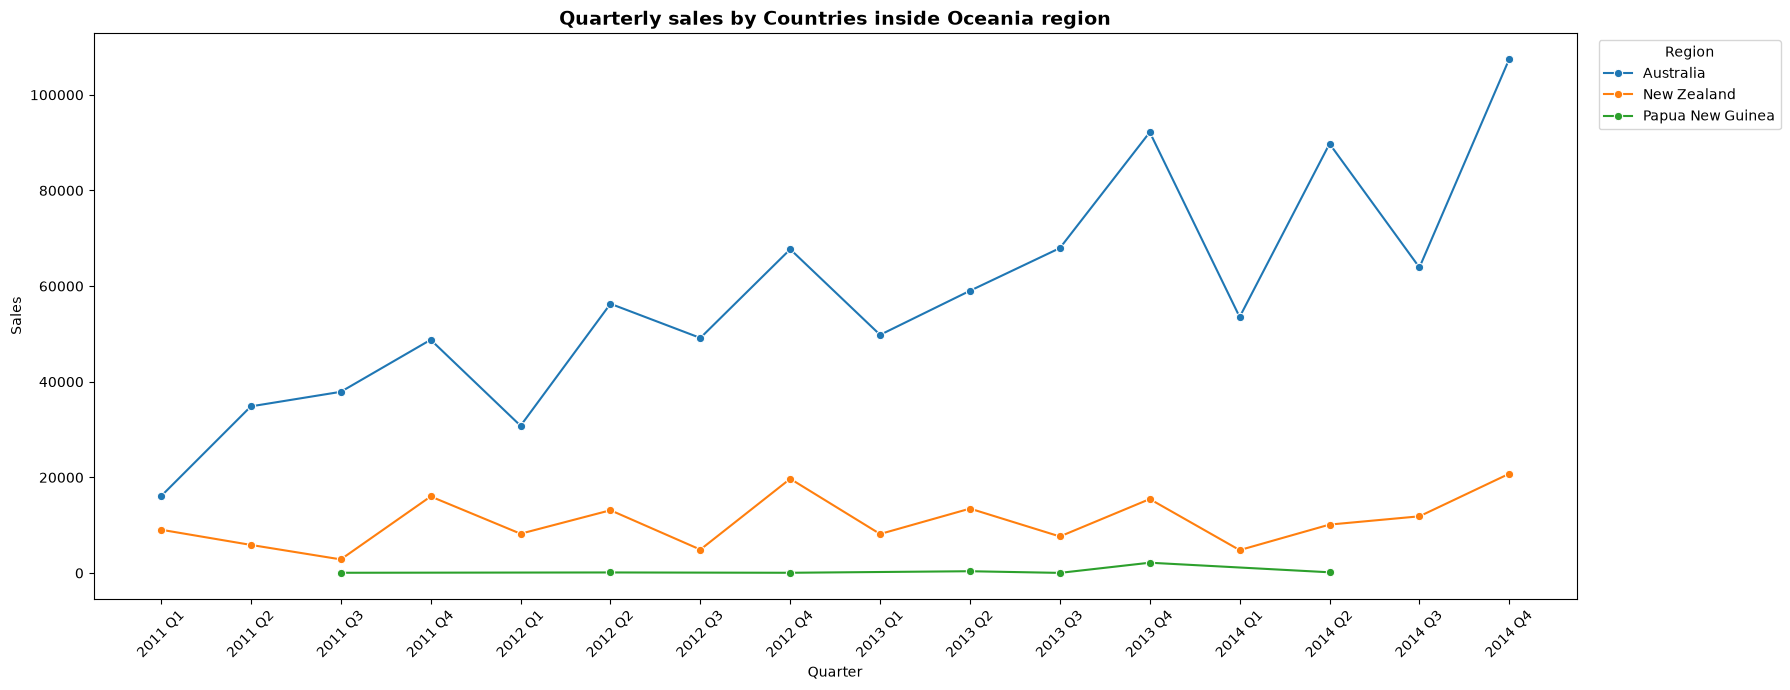

In [101]:
oceania_q=(
    df[df["region"]=="Oceania"].groupby(["year","quarter","country"], as_index=False)["sales"]
    .sum().sort_values(["year","quarter"])
)
oceania_q["period"]=oceania_q["year"].astype(str)+" "+"Q"+oceania_q["quarter"].astype(str)

plt.figure(figsize=(18, 7))
sns.lineplot(data=oceania_q, x="period", y="sales",hue="country", marker="o")
plt.title("Quarterly sales by Countries inside Oceania region", fontsize=14, fontweight="bold")
plt.xlabel("Quarter")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.legend(title="Region", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

Comparing to both **region** and **countries**
 Oceania region **Australia** is the strongest quarterly performer in the top-two data, and top-two sales grew every year from 2011 to 2014.

In [102]:
best_country_q = (
    df.groupby(["year", "quarter", "country"])["sales"].sum()
    .reset_index()
    .sort_values(["year", "quarter", "sales"], ascending=[True, True, False])
    .groupby(["year", "quarter"]).head(1)
)
best_country_q


,year,quarter,country,sales
87,2011,1,United States,74445.0
183,2011,2,United States,86540.0
274,2011,3,United States,143643.0
384,2011,4,United States,179627.0
475,2012,1,United States,68858.0
577,2012,2,United States,89135.0
682,2012,3,United States,130265.0
786,2012,4,United States,182302.0
884,2013,1,United States,92602.0
994,2013,2,United States,135390.0


But when we compare only with Country **UNITED STATES** have the most highest sales because among the regions united states are in multiple region

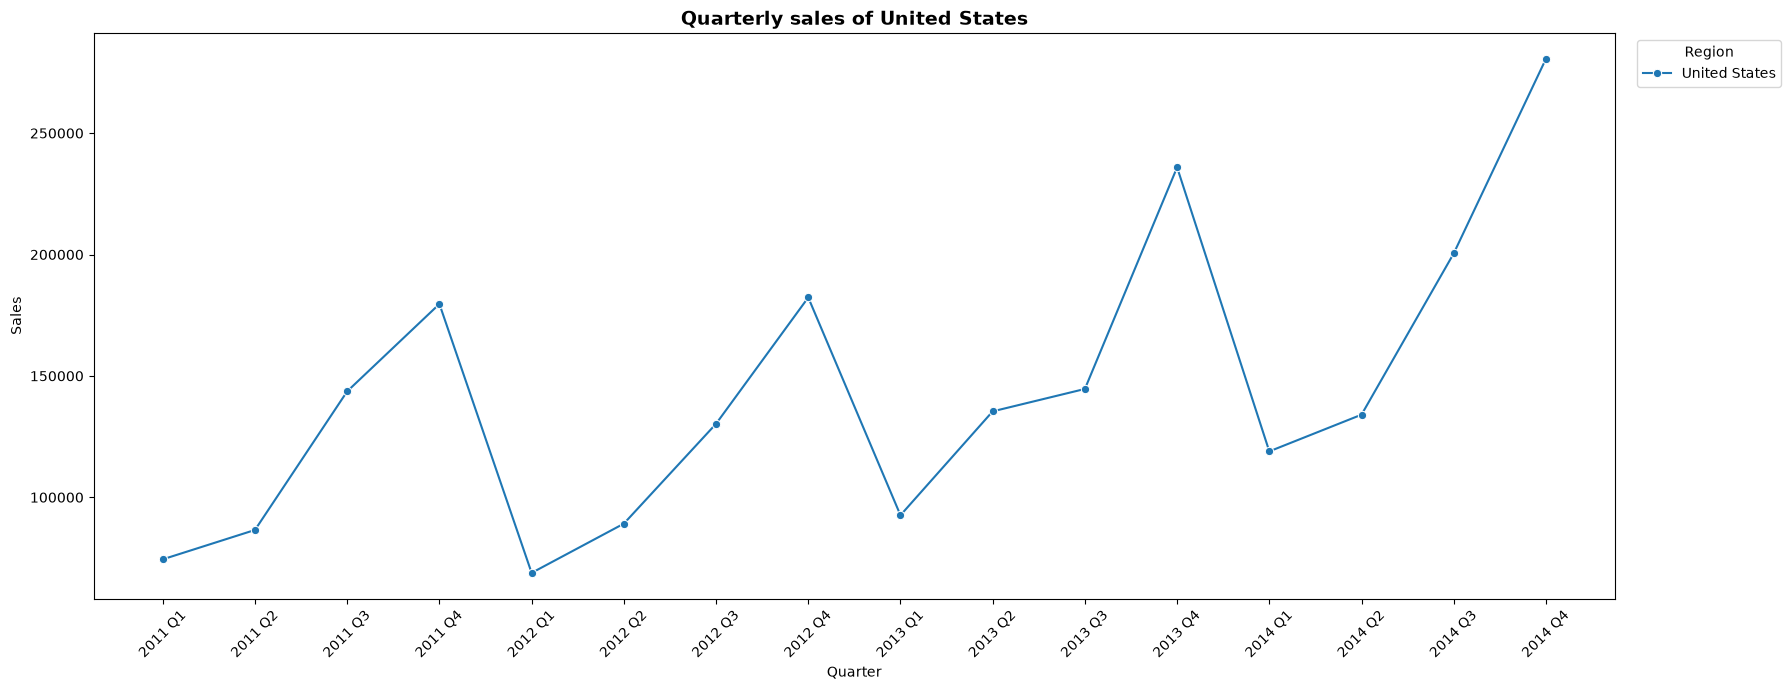

In [116]:

country = best_country_q
country["period"] = country["year"].astype(str) + " Q" + country["quarter"].astype(str)

plt.figure(figsize=(18, 7))
sns.lineplot(data=country, x="period", y="sales", hue="country", marker="o")
plt.title("Quarterly sales of United States", fontsize=14, fontweight="bold")
plt.xlabel("Quarter")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.legend(title="Region", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

But when we only check the country based top sales on quarter top is **USA**

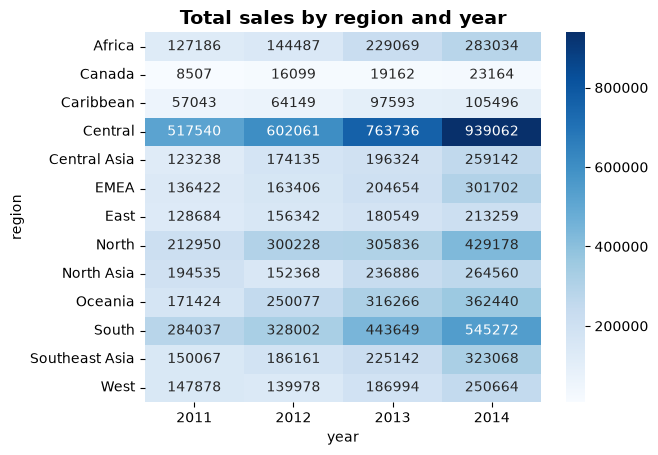

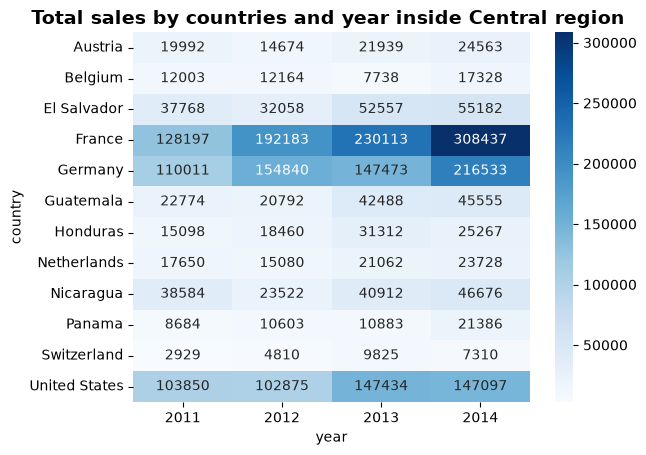

In [117]:

sns.heatmap(df.pivot_table(index="region",columns="year",values="sales",aggfunc="sum"),annot=True,fmt=".0f",cmap="Blues")
plt.title("Total sales by region and year",fontsize=14,fontweight="bold")
plt.show()

central=df[df["region"]== "Central"].pivot_table(index="country",columns="year",values="sales",aggfunc="sum")
sns.heatmap(central,annot=True,fmt=".0f",cmap="Blues")
plt.title("Total sales by countries and year inside Central region ",fontsize=14,fontweight="bold")
plt.show()


### * Over past 4 years **Central** regions performs best on **2014**<br>
### * On Central region **France** out performs every country in all 4 years.

In [105]:
region_wise =(
    df.groupby(["market","region"])
    .agg(
        sales=("sales","sum"),
        profit=("profit","sum"),
        avg_discount=("discount","mean"),
        orders=("order_id","nunique")
    )
)
region_wise["profit_margin_pct"]=(
    region_wise["profit"]/region_wise["sales"]*100
).round(2)

region_wise["avg_discount_pct"]= (region_wise["avg_discount"]*100).round(2)
region_wise = region_wise.drop(columns ="avg_discount").sort_values("profit_margin_pct",ascending= False)
region_wise

sales     profit  orders  profit_margin_pct  \
market region                                                            
Canada Canada            66932.0   17817.39     201              26.62   
APAC   North Asia       848349.0  165578.35    1150              19.52   
       Central Asia     752839.0  132480.18    1026              17.60   
LATAM  North            622620.0  102818.26    1329              16.51   
US     West             725514.0  108418.31    1611              14.94   
EU     North            625572.0   91779.82    1027              14.67   
US     East             678834.0   91522.50    1401              13.48   
EU     Central         1720582.0  215533.96    2576              12.53   
US     South            391750.0   46749.49     822              11.93   
Africa Africa           783776.0   88871.49    2232              11.34   
EU     South            591985.0   65515.79     995              11.07   
APAC   Oceania         1100207.0  120088.89    1744              10.92   
LATAM  Caribbean        324281.0   34571.34     855              10.66   
       Central          600561.0   56163.55    1504               9.35   
US     Central          501256.0   39707.35    1175               7.92   
EMEA   EMEA             806184.0   43897.99    2462               5.45   
LATAM  South            617225.0   28090.48    1456               4.55   
APAC   Southeast Asia   884438.0   17852.49    1517               2.02   

                       avg_discount_pct  
market region                            
Canada Canada                      0.00  
APAC   North Asia                  4.87  
       Central Asia                6.75  
LATAM  North                       6.16  
US     West                       10.93  
EU     North                      13.86  
US     East                       14.54  
EU     Central                     9.13  
US     South                      14.73  
Africa Africa                     15.67  
EU     South                       9.95  
APAC   Oceania                    15.32  
LATAM  Caribbean                  13.58  
       Central                    15.26  
US     Central                    24.01  
EMEA   EMEA                       19.61  
LATAM  South                      18.38  
APAC   Southeast Asia             27.21

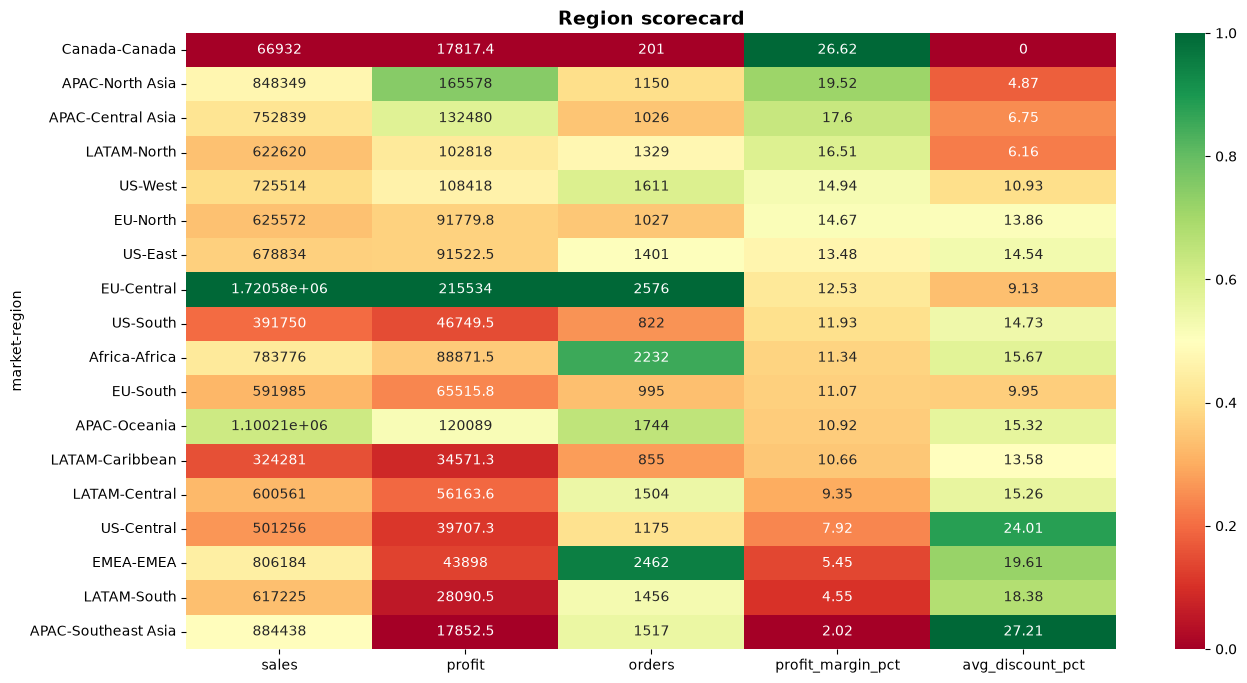

In [106]:
data = region_wise[["sales", "profit", "orders", "profit_margin_pct", "avg_discount_pct"]]

plt.figure(figsize=(15,8))
sns.heatmap((data - data.min()) / (data.max() - data.min()), annot=data.round(2), fmt="g", cmap="RdYlGn")
plt.title("Region scorecard",fontsize=14,fontweight="bold")
plt.show()

* Canada has the highest profit margin **(26.62)**, but only have a small volume<br>
* APAC North Asia have the second highest margin **(19.52)**, and only **(4.87)** average discount% on 848k sales<br>
* EU Central have highest sales of **(1.7M)**, profit of **(215533.96)**, but margin is **(12)** so the * volume speaks the sales
* Southeast Asia is the problem. Brings out $884438 sales but very little amout of profit **(2.02%)**


What happened in Southeast Asia region?

In [107]:
SEAsia=(
    df.loc[(df["market"]=="APAC") & (df["region"]=="Southeast Asia")]
    .groupby(["market","region","country"])
    .agg(
        sales=("sales","sum"),
        profit=("profit","sum"),
        avg_discount=("discount","mean"),
        orders=("order_id","count"),
    )
)
SEAsia["margin_pct"]=(SEAsia["profit"]/SEAsia["sales"]*100).round(2)
SEAsia["avg_discout_pct"]=(SEAsia["avg_discount"]*100).round(2)
SEAsia=SEAsia.drop(columns="avg_discount").sort_values("profit")

SEAsia

sales    profit  orders  margin_pct  \
market region         country                                                   
APAC   Southeast Asia Philippines      183433.0 -16128.20     681       -8.79   
                      Thailand          77048.0  -7308.17     295       -9.49   
                      Myanmar (Burma)   34144.0  -2109.26     136       -6.18   
                      Vietnam           65802.0  -1870.21     265       -2.84   
                      Cambodia          17476.0   4476.54      45       25.62   
                      Singapore         40285.0   8853.06     141       21.98   
                      Indonesia        404887.0  15608.77    1390        3.86   
                      Malaysia          61363.0  16329.96     176       26.61   

                                       avg_discout_pct  
market region         country                           
APAC   Southeast Asia Philippines                34.59  
                      Thailand                   36.25  
                      Myanmar (Burma)            23.62  
                      Vietnam                    23.94  
                      Cambodia                    0.00  
                      Singapore                   0.00  
                      Indonesia                  29.73  
                      Malaysia                    0.00

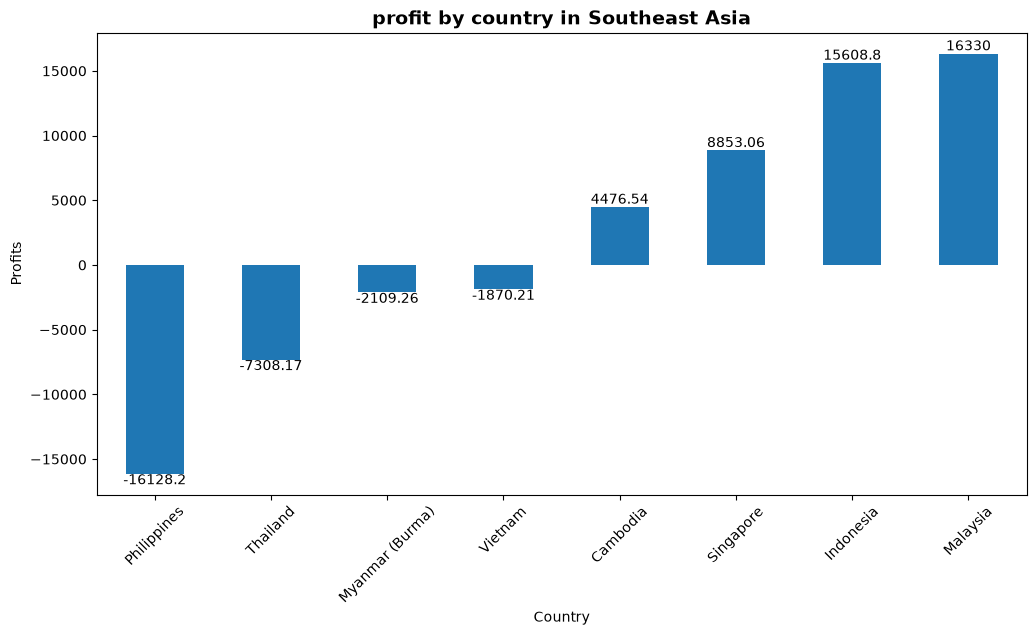

In [108]:
sea=df.loc[(df["market"]=="APAC")&(df["region"]=="Southeast Asia")]
profit_by_country=sea.groupby("country")["profit"].sum().sort_values()

ax=profit_by_country.plot(kind="bar",color="tab:blue",figsize=(12,6))
ax.bar_label(ax.containers[0])
plt.title("profit by country in Southeast Asia",fontsize=14,fontweight="bold")
plt.ylabel("Profits")
plt.xticks(rotation=45)
plt.xlabel("Country")
plt.show()

We found that **Philippines**,**Thailand** and **Myanmar** are the lossing market and highest average discount<br><br><br>
We can see **Indonesia** have the highest sales (404887.0) and largest orders (1390) having **(3.86%)** of profit

In [109]:
SEAsia_loss= df.loc[(df["market"]=="APAC")&(df["region"]=="Southeast Asia")]

cat=(
    SEAsia_loss.groupby(["country","sub_category"])
    .agg(sales=("sales","sum"),profit=("profit","sum"),orders=("order_id","nunique"))
)
cat["margin_pct"]=(cat["profit"]/cat["sales"]*100).round(2)
cat_neg=cat.loc[["Philippines","Thailand","Myanmar (Burma)"]].sort_values("margin_pct")
cat_neg=cat_neg.loc[cat_neg["margin_pct"]<0].sort_values("margin_pct").reset_index()
cat_neg.head(10)

,country,sub_category,sales,profit,orders,margin_pct
0,Thailand,Tables,3822.0,-3187.90,4,-83.41
1,Myanmar (Burma),Tables,2096.0,-1602.79,4,-76.47
2,Thailand,Envelopes,668.0,-338.08,11,-50.61
3,Philippines,Tables,6308.0,-3150.68,10,-49.95
4,Philippines,Supplies,3513.0,-1714.19,39,-48.80
5,Thailand,Supplies,1386.0,-671.40,21,-48.44
6,Thailand,Fasteners,361.0,-167.14,14,-46.30
7,Thailand,Paper,829.0,-357.89,16,-43.17
8,Philippines,Paper,1853.0,-746.99,34,-40.31
9,Philippines,Storage,7404.0,-2982.48,35,-40.28


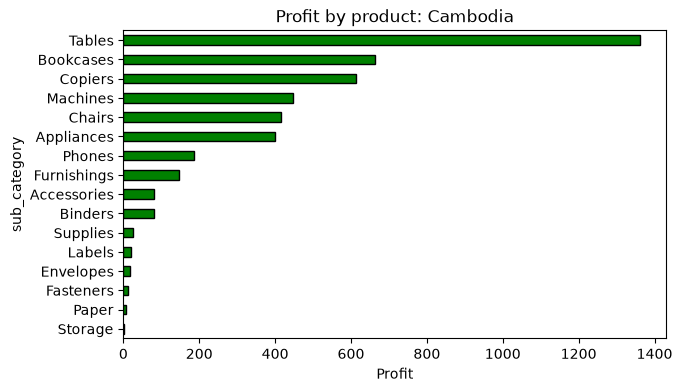

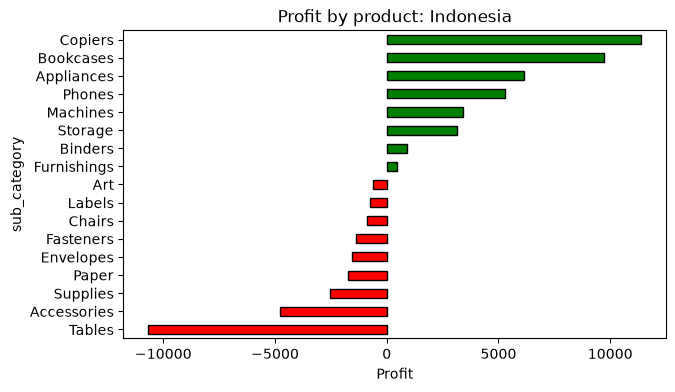

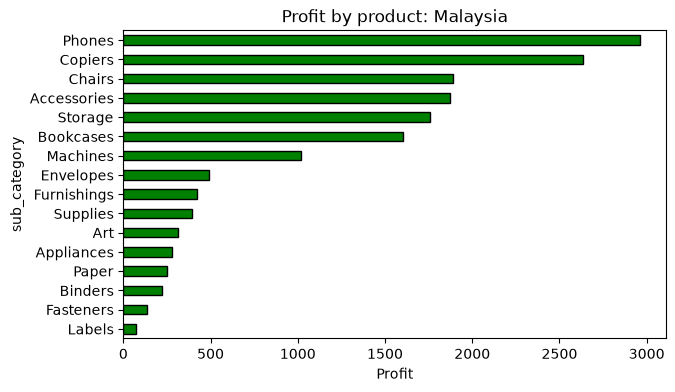

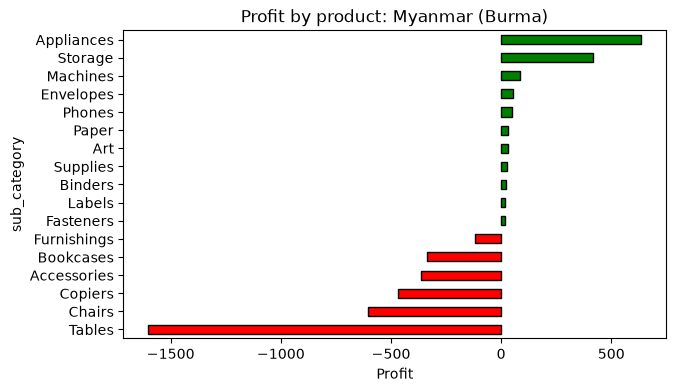

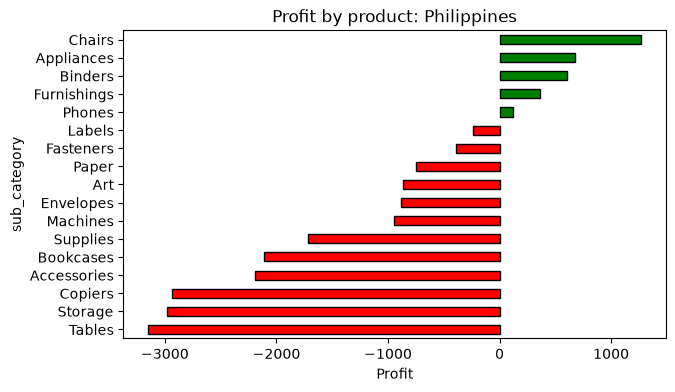

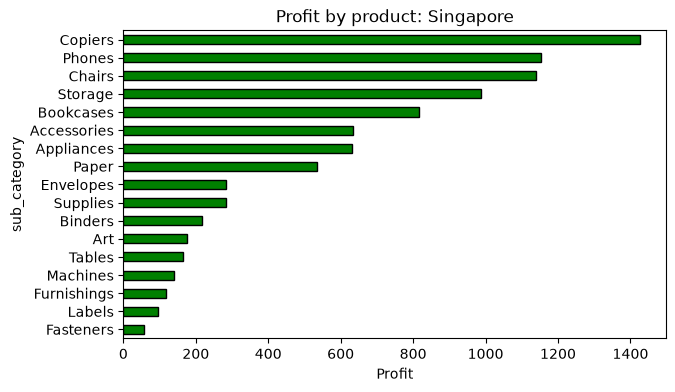

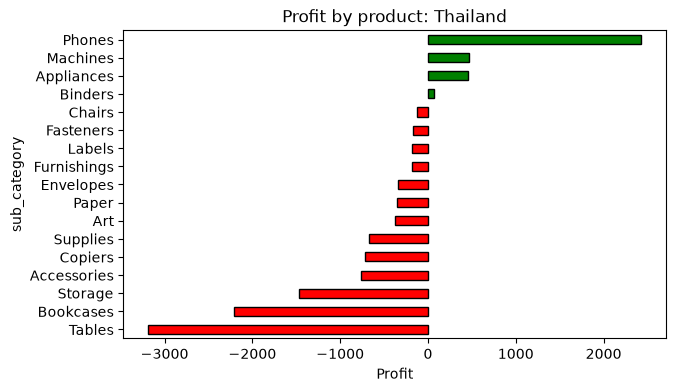

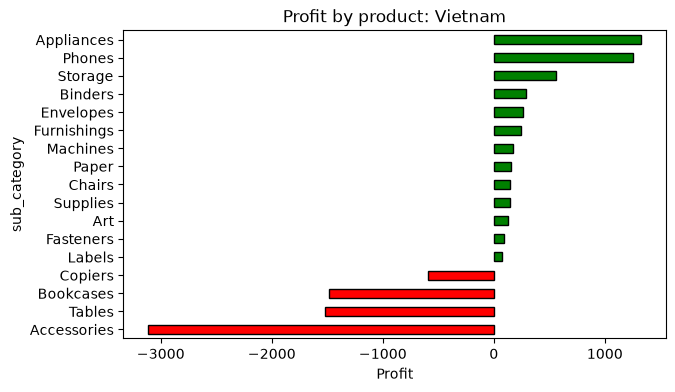

In [110]:
for country, grp in sea.groupby("country"):
    s = grp.groupby("sub_category")["profit"].sum().sort_values()
    plt.figure(figsize=(7, 4))
    s.plot(kind="barh", color=["red" if v < 0 else "green" for v in s], edgecolor="black")
    plt.title(f"Profit by product: {country}")
    plt.xlabel("Profit")
    plt.show()

* **Tables** are the major product problem that appears in all 3 countires loses of **7.9k** on **12.2k sales** a margin of **-65%** <br>
* **Thailand** is most loss making rows of **4.7k loss** and **7.1k sales** 
<br>

*  **Philippines** has the largest money loss in  4 rows total of **8.6k** loss on **19.1k** of sales    **-45%**

### We found that these are the products which causing loss in Southeast Asia.

#### Southeast Asia’s margin (2.0%) is well below the company average. Four countries account for about 27k in losses, and loss-making countries carry deeper discounts than profitable ones.

In [111]:
sea = df[(df["market"] == "APAC") & (df["region"] == "Southeast Asia")]
sea.groupby("sub_category")["profit"].sum().sort_values()

sub_category
Tables        -18618.33
Accessories    -8641.47
Supplies       -4034.20
Paper          -1859.00
Envelopes      -1641.16
Fasteners      -1602.29
Art            -1189.77
Labels          -870.34
Furnishings     1451.56
Binders         2395.24
Storage         2418.19
Chairs          3229.62
Machines        4782.76
Bookcases       6667.33
Appliances     10556.67
Copiers        11355.55
Phones         13452.13
Name: profit, dtype: float64

## Solution Summary

**Problem:** Southeast Asia earns a 2.0% profit margin on about 884k in sales, the lowest margin among the large regions. Four countries (Philippines, Thailand, Myanmar, Vietnam) lose money overall, and Tables, Accessories, and Supplies are the sub-categories with the largest losses in the region.

**Root cause:** Discounting. Across the company, 92.2% of total loss value comes from order lines with discounts above 20%. Chairs follow the same pattern: 17.6% margin at 0–20% discount, −10.3% at 21–40%, and −81.6% above 40%. Southeast Asia gives deep discounts more often than the rest of the company, so its margin is low even though its performance at each discount level is similar to the rest of the business.

**Recommended solution:**

1. **Cap discounts at 20% company-wide.** Lines above 20% should require approval.
2. **Pilot the cap in Southeast Asia first,** since it has the most deep-discount lines and the lowest margin.
3. **Review pricing for Tables, Accessories, and Supplies** in Southeast Asia, since these lose money even before deep discounts are considered (verify this against the discount-band check for those sub-categories).

**Expected impact:** Capping discounts should reduce the share of loss-making lines and lift the region's margin. The size of that lift depends on how much volume shifts from deep discounts to the capped range, which the data does not show directly. Run a simulation before quoting a number. Set the cap at a level you can justify, then rerun the margin calculation with discounted lines limited to that cap.

**How to measure success:** Track margin by discount band and the share of order lines with losses, before and after the cap. Monitor Southeast Asia's margin against the company average.

**Limitations to state:**

- The data has no cost detail (staff, rent, overheads), so profit is before those costs.
- The analysis is descriptive. It shows that discounts and losses move together, not that every loss is caused by discounts.
- The Chairs check covers one product. The discount-band check still needs to run on Tables and Supplies.
- The 92.2% figure is company-wide. Run the same calculation on the Southeast Asia subset before quoting it for the region.
- The source must be credited before submission.